<a href="https://colab.research.google.com/github/bcramp/ML/blob/main/HW7/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

HW 7

Title: Assignment Analysis

Name: Brennen Cramp

Date: 11/9/2026

---

# Analysis
---

1. Feature scaling is essential prior to executing distance/density-based clustering algorithms (K-Means, DBSCAN, and HDBSCAN) because these alorithms rely on Euclidean distance metrics to determine similarity and when features exist on completely different scales, features with large numerical ranges dominate the distance calculations, rendering smaller-scale features irrelevant during computation. Unscaling these features would heavily distort the ditance calculations needed for clustering thus rendering any feature with smaller scales relatively uneffective. For instance, the 'proline' feature has a minimum value of 278 with a maximum value of 1680 with an average/mean of 746.893258 and a standard deviation of 314.907474 while the 'nonflavanoid_phenols' feature has a minimum of 0.13, maximum of 0.66, average of 0.361854, and a standard deviation of 0.124453. This means that the 'proline' feature has values in a range of 1402 while the 'nonflavanoid_phenols' feature has values in a range of 0.53 where when the Euclidean distance is trying to be computed between 2 wine samples without scaling, if both samples are identical except that their 'proline' differs by just 50 to 100 (a tiny fraction of the range so not that much different in samples), this would greatly effect the distance calculated despite both samples being relatively the same. Conversely, even if the absolute opposite extremes of the 'nonflavanoid_phenols' feature are represented (meaning it is a massive compositional difference in the wine samples), the distance would barely change in its calculation. In an unscaled environment, the algorithm completely ignores crucial chemical nuances like the 'nonflavanoid_phenols' feature, 'hue' feature, or 'alcohol' feature and clusters the wines almost exclusively based on their 'proline' content within the sample. Even analyzing the "... BEFORE Scaling" boxplot from Task 1 visibly shows 'proline' and the second widest feature, 'magnesium' (min = 70.0 and max = 162.0), stretch across massive horizontal spaces while the other 11 features look like flat, vertical lines since their range and min/max values are miniscule when compared to 'proline' and 'magnesium'. Looking at the "... AFTER Scaling" boxplot shows that these scaled features are more "equal" in their comparisons against each and every feature. Post-standardization (Z-score scaling), every feature is centered around 0 with unit variance, forcing the algorithms to weigh each chemical dimension equally and fairly in comparison to one-another.

2. Both the Elbow Method and Silhouette Analysis from Task 2 perfectly aligned with the true, natural structure of the Wine dataset, suggesting that k=3 is the mathematically optimal number of clusters. These evaluation metrics also align directly with the 3 true wine cultivars ('class_0', 'class_1', and 'class_2'). For the "Elbow Method Curve" graph, the Within-Cluster Sum of Squares (WCSS/Inertia) drops sharply from k=1 down to k=2, then again from k=2 to k=3 where the inflection point is clear in that the drops from k=1 to k=3 versus from k=3 to beyond, are drastically different. The "elbow" was perfectly formed in the graph at k=3 where any k-value after this point, the curve flattens out dramatically, indicating that partitioning the data into 4 or more clusters provides diminishing returns in explaining variance. For the "Silhouette Scores Curve" graph, the silhouette score measures how well-separated and tightly cohesive the clusters and where the curve reaches its maximum peak at k=3 with a score of roughly 0.28. Due to the score dropping sharply for k=4 and drops off a cliff at k=5, it confirms that partitioning the space into 3 clusters maximizes inner-cluster density while ensuring the clean boundary separation which is visible in the PCA plot for Task 3. Additionally, no discrepancies were observed because it is common in more complex datasets for these methods to disagree from one-another. This could be an indicator of the Wine dataset features showing strong and clear separation among chemical profiles and when the features are properly standardized, the data points naturally form three distinct classes, allowing both distance-based metrics to distinguish the wine's profile without any confusion.

3. The fundamental difference in clustering behavior between K-Means, DBSCAN, and HDBSCAN stems directly from their core mathematical calculations and how each of them define a cluster. For K-Means as a partitioning algorithm, it acts as an all-inclusive assignment model and it requires a predefined number of cluster (k=3) and relies on a global objective function to minimize the distance between every data point and its nearest centroid. K-Means divides the entire feature space using clean cuts (Voronoi regions - as seen in the plot for Task 3) so each sample must be assigned to a cluster despite how far it might sit from the calculated center. For K-means, points on the absolute edges or laying right in the middle between two groups are forced into a hard assignment. In contrast, for DBSCAN, it defines clusters as continuous areas of high point density separated by regions of low point density, using the experimented hyperparameters (eps=2.3 and min_samples=3) to strcitly evaluate the local neighborhoods in the 13-dimensional space. Samples that fail to meet those local density requirements (i.e. they do not have at least 3 neighbors within a radius of 2.3 units) are labled as noise points (-1). The most optimal values I found when experimenting [values such as (eps, min_samples): (2.3, 4), (2.0, 3), (1.7, 4), etc.] were eps=2.3 and min_samples=3 which discovered 3 clusters and flagged 32 noise points where these noise points lie on the outer edges and decision boundaries of the main groupings or in the gaps between clusters (seen in the plot for Task 5). For HDBSCAN, it expands upon the DBSCAN method by taking a hierarchical, varying-density approach where instead of cutting the data with a single fixed radius, it looks at how clusters persist across a range of density threshholds. When using the suggested hyperparameters (min_cluster_size=5, min_samples=5), it discovered 2 clusters and flagged 58 noise points which is not the best clustering given that I know there are 3 classifications for the samples. It seemed to have merged two of the closer, more continuous groups into a single cluster while isolating a second tight group (visible as green-ish dots) on the plot produced from Task 6. It reclassified a much larger portion of the points (58 points) as noise because they possibly belonged to branches of the hierarchy that were too sparse or unstable to form standalone clusters. In summation, K-means assumes that every point belongs to a group (thus there should never be noise) and shapes its boundaries globally, encompassing all those points while DBSCAN and HDBSCAN look at the data locally where they isolate the dense cores of the sample profiles and cleanly discard low-density fringe samples as noise to protect the purity of the clusters.

4. The fundamental operational difference between standard DBSCAN and HDBSCAN lies in how they define density thresholds and extract clusters from that data. This distinction becomes critical when analyzing datasets like the Wine dataset, where different chemical groups can form clusters with much different local densities. Standard DBSCAN relies on a single, fixed global search radius (eps) which is a vulnerability/limitation. When DBSCAN is executred, the algorithm draws a hypersphere of exactly eps-radius around every data point to count its neighbors. If a dataset contains variable densities, meaning one cluster is packed closely together while another cluster is spread over a wider area, DBSCAN faces a mathematical issue. If a large eps is chosen to capture the loose cluster, the tight clusters will merge into a single, massive cluster and, vice-versa, if a small eps is chosen to separate the tight clusters, the loose cluster will be completely wiped out and misclassified as noise points. HDBSCAN eliminates the need to guess a single eps-parameter by looking at density hierarchically. It operates by first transforming the space where it will calculate a reachable distance among the neighboring points to push further points away to clean up the noise. Then, it constructs a hierarchical, single-linkage cluster tree (similar to the one from Task 7) which tracks how points connect and merge at every possible distance threshhold instead of simply one threshold. Finally, it will simplify the complex tree based on the min_cluster_size hyperparameter where HDBSCAN measures the volume and stability of each branch. This is the main reason why HDBSCAN's hierarchical, stability-based approach will overcome DBSCAN's single global eps parameter when clustering chemical datasets with varying local densities (however, not in my particular case which I will further address in **question 5**). A branch that remains tightly packed and can "survive" over a wide range of distance thresholds is recognized as a highly stable cluster. Sparser and unstable branches that dissolve quickly are dropped and labeled as noise (-1) which allows HDBSCAN to discover clusters of completely different densities at the same time. This explains why HDBSCAN was able to isolate the dense core profiles of the wine samples (condensing them into 2 highly stable clusters, even though incorrect, and most likely due to the hard requirement of setting both the parameters to be 5) while dynamically discarding 58 points as noise, avoiding the forced global radius constraint that standard DBSCAN relies on.

5. The results of the comparative classification experiment from Task 8 reveal how effectively unsupervised cluster structures translate into actionable feature representations for the Random Forest Classifier to predict the true ground-truth wine cultivars. When looking at performance, K-Means (where k=3) achieved both the highest silhouette score of 0.2807 and a very high supervised accuracy of 97.22%. This high performance occurs due to K-Means partitioning the full 13-dimensional space into 3 discrete and all-inclusive clusters that align perfectly with the true boundaries of the 3 wine cultivators ('class_0', 'class_1', and 'class_2'). In second place, DBSCAN produced a silhouette score of 0.1382 and a supervised accuracy of 77.78%. While DBSCAN successfully extracted 3 distinct clusters, its performance dropped because it stripped away 32 samples as noise and the downstream Random Forest Classifier struggled to map this uniform "noise" label back to the true underlying classes since those 32 samples actually spanned across multiple true cultivars. In last place, performance-wise, HDBSCAN returned a silhouette score of 0.1381 (only a 0.0001 difference from DBSCAN) and had the lowest supervised accuracy at 69.44%. This can be associated with HDBSCAN merging 2 of the closer classes into a single, stable cluster and categorized a massive portion of the dataset (58 points) as noise, which casued the Random Forest Classifier to lose too much granular class information. It was forced to predict true targets using essentially only 2 structural pseudo-labels alongside a massive pool of noise. While HDBSCAN is theoretically a more advanced and flexible algorithm than standard DBSCAN, its hierarchical density-stabilization mechanics actually worked against it in this case for the downstream supervised prediction task. Traditional DBSCAN flagged 32 points as noise based on the rigid global radius while HDBSCAN evaluated cluster stability across a full tree hierarchy and stripped away too many points as noise (roughly 33% of the entire 178-sample dataset). By labeling all those points as noise, HDBSCAN threw out a massive amount of chemical variance and when these pseudo-labels are fed into a Random Forest, the classifier is forced to look at those 58 points and map a single label (-1) to 3 completely different true cultivars. This could have been due to HDBSCAN being too aggressive in its quest for "pure" dense cores, stripping the downstream classifier of the contextual boundaries it needed to make accurate predictions. Additonally, under-clustering and class-merging could have caused HDBSCAN (when forced to its hierarchical constraints of min_cluster_size=5 and min_samples=5) to determine that 2 of the true wine classes were not distinct enough in their density variations to remain separate branches on the condensed tree, thus why it only created 2 clusters. In all, there are structual limitations of density mapping of unsupervised clusters to supervised class lavels when dealing with noise and density-based grouping. Unsupervised cluster quality does not always equal how well those groupings help predict a target label or solve a downstream task which is highlighted in the Task 8 results. When dealing with density-based groupings, algorithms like DBSCAN and HDBSCAN focus entirely on isolating the dense cores which is perfect for cleaning up outliers but it will introduce major bottlenecks when mapping to supervised class labels. Density models will group all fringe points into a single categorical value of noise (-1) which will destroy the variance within those points, forcing a downstream model to guess their true classes essentially blindly. In the real world, not all datasets look like dense groupings nor are seperated by empty space and they will almost regularly blend together at borders and forcing a filter of density on continuous data could break genuine class structures apart if their geometries are misaligned in any way based on their complex features.

# **Feature Distributions BEFORE and AFTER Scaling (Task 1):**

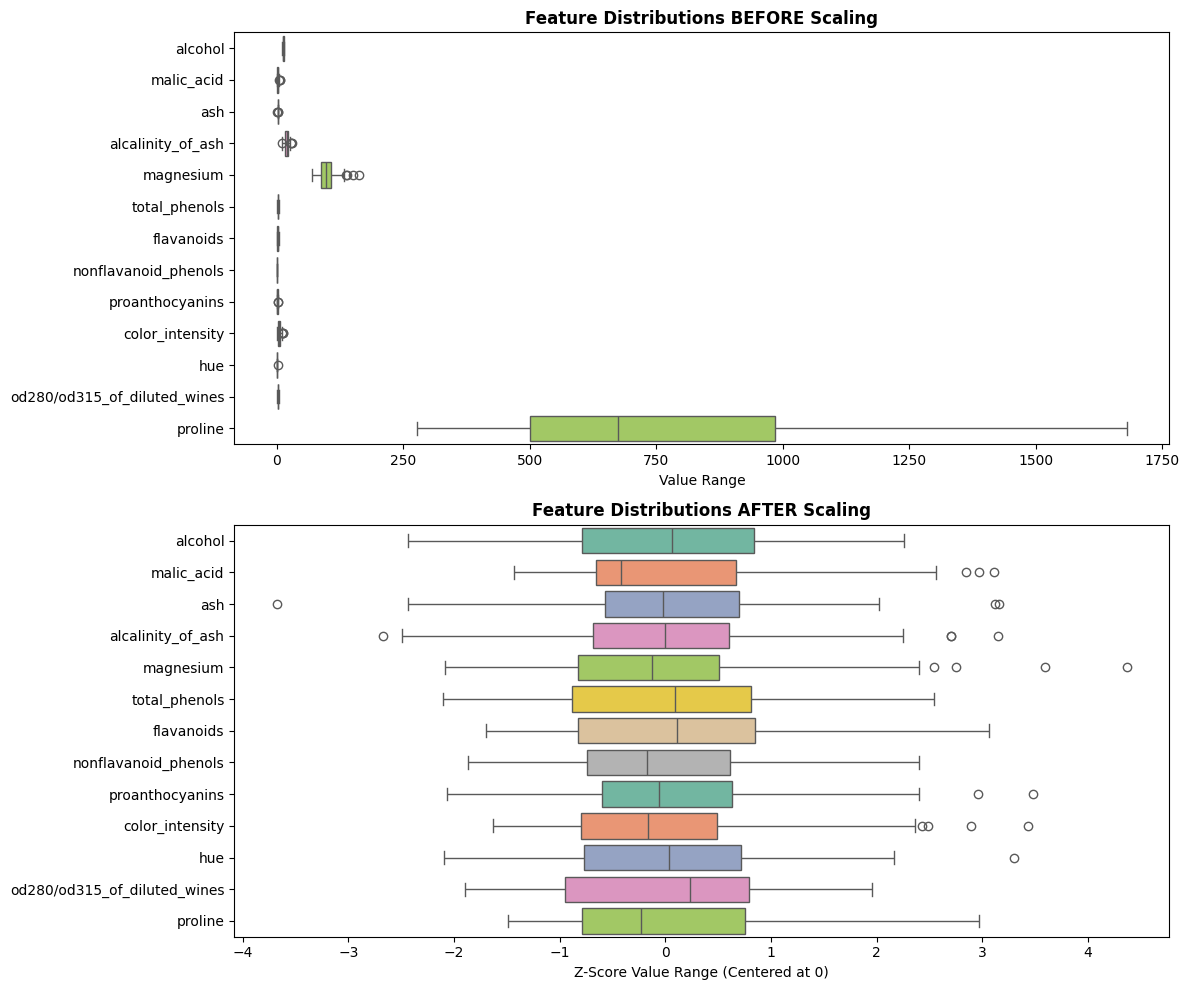

# **The Elbow Method Curve and The Silhouette Scores Curve(Task 2):**

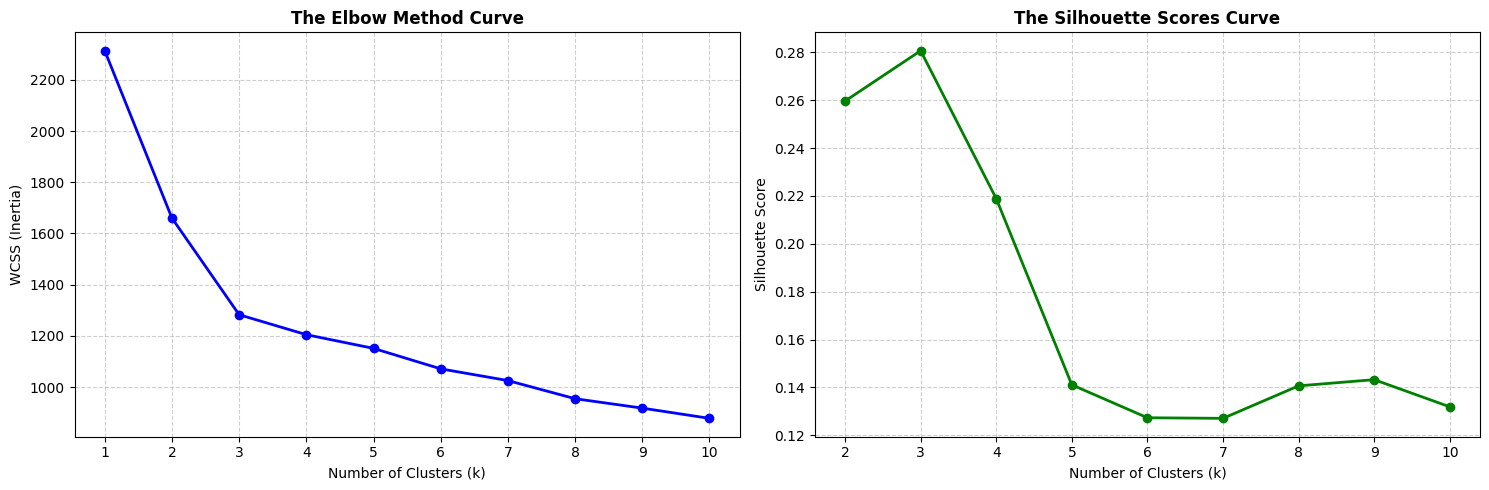

# **K-Means Decision Boundaries (Voronoi Mapping) (2D PCA Space) (Task 3):**

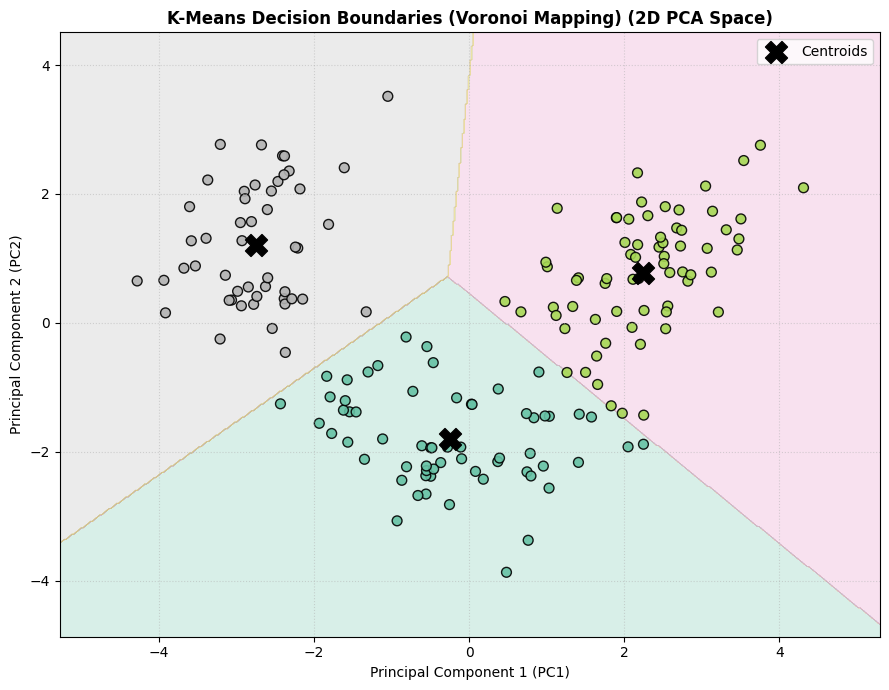

# **Soft Clustering Distance Heatmap (Task 4):**

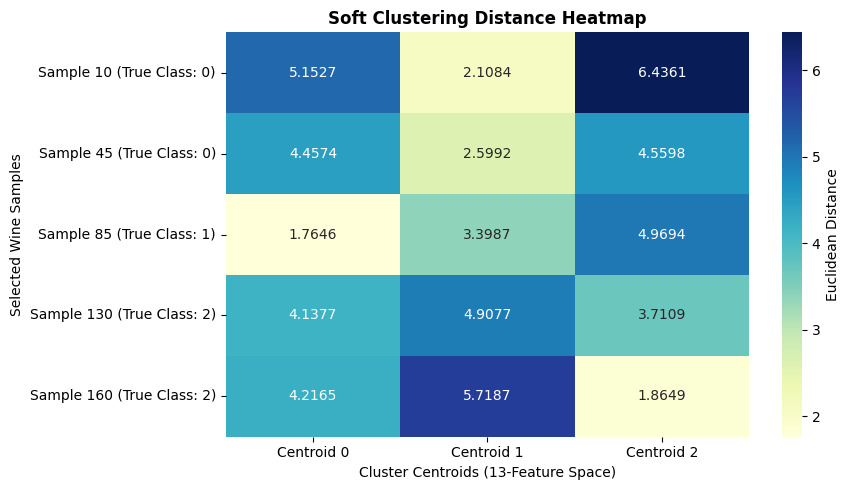

# **DBSCAN Clustering Map (Projected onto 2D PCA Space) (Task 5):**

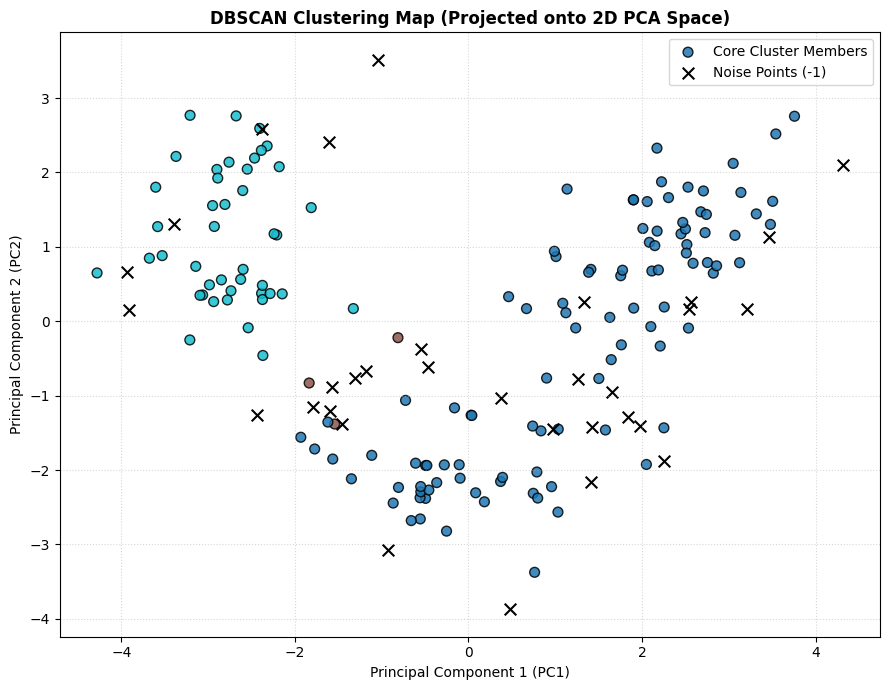

# **HDBSCAN Clustering Map (Projected onto 2D PCA Space) (Task 6):**

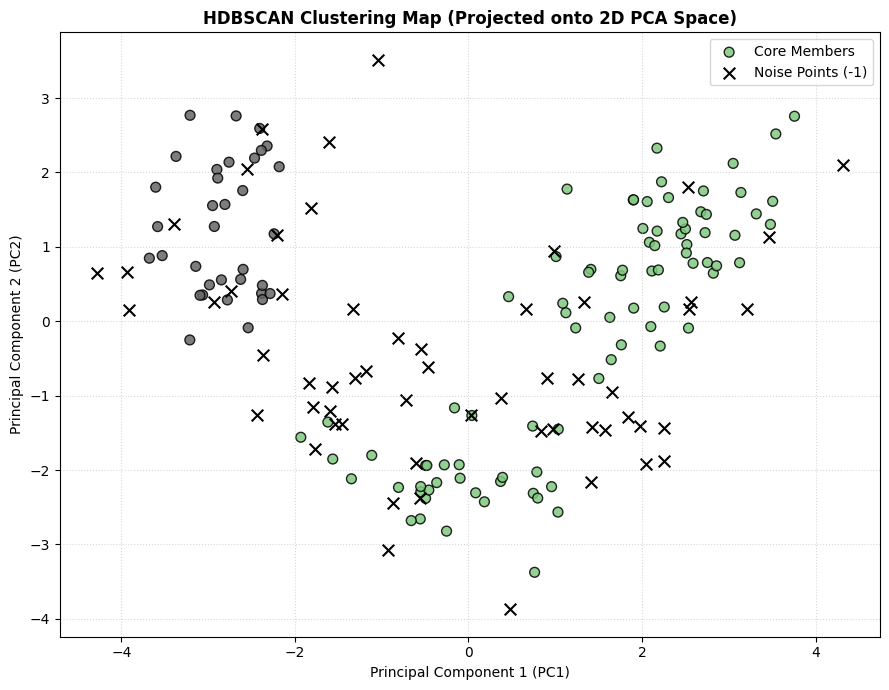

# **Hierarchical Clustering Dendrogram (Single Linkage Tree) (Task 7):**

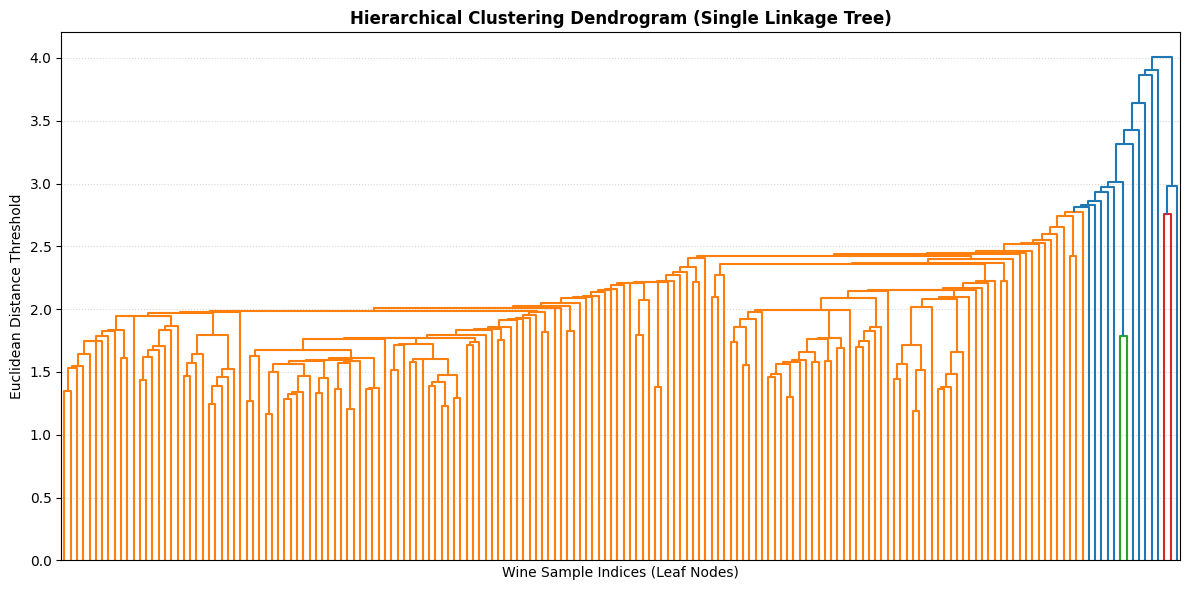

# **Supervised Accuracy vs. Unsupervised Cluster Silhouette Scores (Task 8):**

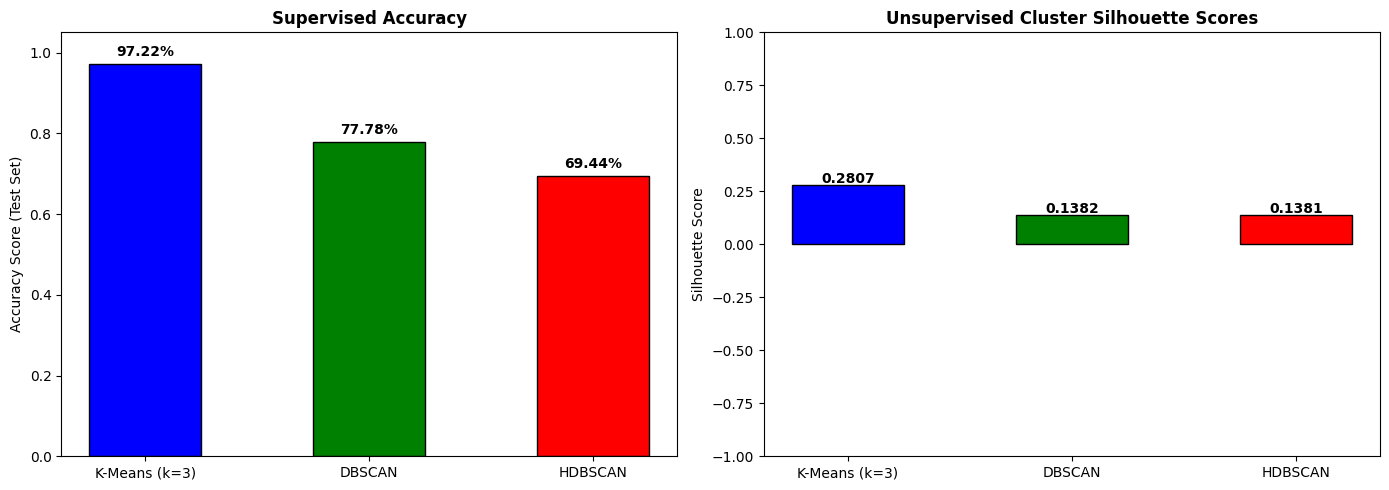